# Exploración y limpieza de Global Findex 2017
**Proyecto de Ciencia de Datos — Grupo 10**  
Isaias Carte y Rodrigo Ramirez

**Pregunta:** ¿Qué características sociodemográficas y de acceso tecnológico permiten predecir si un adulto de América Latina y el Caribe posee una cuenta en una institución financiera?

Esta fase inspecciona el original, documenta las codificaciones y la cobertura geográfica, prepara casos completos y describe asociaciones. No se entrenan modelos, no se hace una partición de datos y no se calculan métricas de clasificación. Los descriptivos se refieren a personas de **15 años o más**, según el universo de Findex.

## 1. Preparación y fuentes
Ejecutar todas las celdas en orden con el entorno del proyecto. Las rutas parten de la raíz del repositorio o de `notebooks/`. No se necesita conexión a internet para ejecutar este notebook.

El archivo `data/raw/micro_world.csv` fue extraído, sin modificaciones, de `WLD_2017_FINDEX_v02_M_CSV.zip`. Las sintaxis del ZIP ASCII/SPSS/SAS y los metadatos descargados se conservan en `docs/source/`. `docs/source_manifest.json` registra la procedencia y las huellas SHA-256 de los archivos extraídos. El original se lee, nunca se sobrescribe.

Fuentes verificadas: [catálogo y metodología de la encuesta 2017](https://microdata.worldbank.org/index.php/catalog/3324/study-description), [metadatos oficiales del archivo](https://microdata.worldbank.org/metadata/export/3324/json), [metodología 2017](https://thedocs.worldbank.org/en/doc/d4be0980516591d047aeb1945eab6598-0050062022/original/Methodology2017.pdf), [ReadMe 2017](https://microdata.worldbank.org/catalog/3324/download/44602). La población objetivo es civil, no institucionalizada, de 15 años o más.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path(".")
if not (ROOT / "src/data_processing.py").is_file():
    ROOT = Path("..")
assert (ROOT / "src/data_processing.py").is_file(), "Abrir desde la raíz o notebooks/."
sys.path.insert(0, str(ROOT))
from src.data_processing import (
    MODEL_COLUMNS, SELECTED_COLUMNS, LAC_REGION, LAC_HIGH_INCOME, LABELS,
    load_findex, filter_lac, clean_missing_values, prepare_model_dataset,
    data_quality_summary, regional_weight_reference, regional_weights,
)
from src.utils import COUNTRY_LABELS, account_by_group, plot_account_rates

RAW_PATH = ROOT / "data/raw/micro_world.csv"
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
PROCESSED = ROOT / "data/processed/findex_lac_clean.csv"
for folder in [TABLES, FIGURES, PROCESSED.parent]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 100})

def save_table(table, filename):
    table.to_csv(TABLES / filename, index=False, float_format="%.10g")

versions = {name: importlib.metadata.version(name) for name in
            ["pandas", "numpy", "matplotlib", "jupyter", "nbformat", "nbclient", "ipykernel"]}
(ROOT / "docs/exploration_environment.json").write_text(
    json.dumps({"python": sys.version.split()[0], "packages": versions}, indent=2) + "\n",
    encoding="utf-8",
)
source_hash_before = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
manifest = json.loads((ROOT / "docs/source_manifest.json").read_text(encoding="utf-8"))
expected_hash = next(item["sha256"] for item in manifest if item["destination"] == "data/raw/micro_world.csv")
assert source_hash_before == expected_hash, "El original no coincide con el ZIP de procedencia."
data = load_findex(RAW_PATH)
print(f"Dimensiones originales: {data.shape[0]:,} filas y {data.shape[1]} columnas.")

Dimensiones originales: 154,923 filas y 105 columnas.


## 2. Inspección inicial del archivo mundial
Se enumeran los nombres de las columnas, pero se muestran observaciones y tipos detallados solo de las variables seleccionadas. Los vacíos del CSV se leen como faltantes. Las frecuencias originales todavía incluyen códigos de no respuesta.

In [2]:
print("Nombres de las columnas:")
for start in range(0, len(data.columns), 12):
    print(", ".join(data.columns[start:start + 12]))
print("\nTipos de datos del archivo completo:")
display(data.dtypes.astype(str).value_counts().rename_axis("tipo").to_frame("columnas"))
columns = [c for c in SELECTED_COLUMNS if c in data]
assert columns == SELECTED_COLUMNS, "Revisar variables auxiliares ausentes."
display(data[columns].dtypes.astype(str).rename_axis("variable").to_frame("tipo"))
display(data[columns].head())
missing_original = data.isna().sum().rename_axis("variable").reset_index(name="faltantes")
missing_original["faltantes_pct"] = 100 * missing_original["faltantes"] / len(data)
save_table(missing_original, "original_missing_values.csv")
print(f"Faltantes originales en todo el archivo: {int(data.isna().sum().sum()):,} celdas.")
display(missing_original.loc[missing_original.variable.isin(columns)])

Nombres de las columnas:
economy, economycode, regionwb, pop_adult, wpid_random, wgt, female, age, educ, inc_q, emp_in, fin2
fin3, fin4, fin5, fin6, fin7, fin8, fin9, fin10, fin11a, fin11b, fin11c, fin11d
fin11e, fin11f, fin11g, fin11h, fin14a, fin14b, fin14c, fin15, fin16, fin17a, fin17b, fin19
fin20, fin21, fin22a, fin22b, fin22c, fin24, fin25, fin26, fin27a, fin27b, fin27c1, fin27c2
fin28, fin29a, fin29b, fin29c1, fin29c2, fin30, fin31a, fin31b, fin31c, fin32, fin33, fin34a
fin34b, fin34c1, fin34c2, fin35, fin36, fin37, fin38, fin39a, fin39b, fin39c1, fin39c2, fin40
fin41, fin42, fin43a, fin43b, fin43c1, fin43c2, fin44, fin45, fin46, fin47a, fin47b, fin47c1
fin47c2, fin47c3, fin47c4, fin47c5, mobileowner, fin48, account_fin, account_mob, account, saved, borrowed, receive_wages
receive_transfers, receive_pension, receive_agriculture, pay_utilities, remittances, pay_onlne, pay_onlne_mobintbuy, pay_cash, pay_cash_mobintbuy

Tipos de datos del archivo completo:


,columnas
tipo,
float64,74
int64,28
str,3


,tipo
variable,
account_fin,int64
age,float64
female,int64
educ,float64
inc_q,int64
emp_in,float64
mobileowner,float64
economy,str
economycode,str


,account_fin,age,female,educ,inc_q,emp_in,mobileowner,economy,economycode,regionwb,wgt
0,0,18.0,1,2.0,1,1.0,1.0,Afghanistan,AFG,South Asia,1.936754
1,0,25.0,2,1.0,5,0.0,1.0,Afghanistan,AFG,South Asia,0.332867
2,0,40.0,2,1.0,2,0.0,1.0,Afghanistan,AFG,South Asia,1.338906
3,0,45.0,2,1.0,1,0.0,2.0,Afghanistan,AFG,South Asia,0.275619
4,0,30.0,1,1.0,4,1.0,1.0,Afghanistan,AFG,South Asia,0.629304


Faltantes originales en todo el archivo: 7,232,284 celdas.


,variable,faltantes,faltantes_pct
0,economy,0,0.000000
1,economycode,0,0.000000
2,regionwb,1000,0.645482
5,wgt,0,0.000000
6,female,0,0.000000
7,age,451,0.291112
8,educ,10,0.006455
9,inc_q,0,0.000000
10,emp_in,1000,0.645482
88,mobileowner,2,0.001291


In [3]:
cardinality = data[columns].nunique(dropna=True).rename_axis("variable").reset_index(name="valores_unicos")
display(cardinality)
frequencies = []
for column in columns:
    freq = data[column].value_counts(dropna=False).rename_axis("valor").reset_index(name="n")
    freq.insert(0, "variable", column)
    freq["porcentaje_no_ponderado"] = 100 * freq["n"] / len(data)
    frequencies.append(freq)
    if column in ["account_fin", "female", "educ", "inc_q", "emp_in", "mobileowner", "regionwb"]:
        print(f"\n{column} (original mundial, sin ponderar)")
        display(freq)
# Guardar todas las frecuencias, incluso edades y pesos, sin imprimir miles de valores.
save_table(pd.concat(frequencies, ignore_index=True), "selected_value_frequencies_original.csv")
display(data[["age", "wgt"]].describe(percentiles=[.01, .25, .5, .75, .99]))

,variable,valores_unicos
0,account_fin,2
1,age,85
2,female,2
3,educ,5
4,inc_q,5
5,emp_in,2
6,mobileowner,4
7,economy,144
8,economycode,144
9,regionwb,8



account_fin (original mundial, sin ponderar)


,variable,valor,n,porcentaje_no_ponderado
0,account_fin,1,92925,59.98141
1,account_fin,0,61998,40.01859



female (original mundial, sin ponderar)


,variable,valor,n,porcentaje_no_ponderado
0,female,2,83593,53.957773
1,female,1,71330,46.042227



educ (original mundial, sin ponderar)


... (6 outputs left out)

,variable,valor,n,porcentaje_no_ponderado
0,mobileowner,1.0,127777,82.477747
1,mobileowner,2.0,26756,17.270515
2,mobileowner,4.0,264,0.170407
3,mobileowner,3.0,124,0.080040
4,mobileowner,NaN,2,0.001291



regionwb (original mundial, sin ponderar)


,variable,valor,n,porcentaje_no_ponderado
0,regionwb,Sub-Saharan Africa (excluding high income),35000,22.591868
1,regionwb,High income: OECD,31066,20.052542
2,regionwb,Europe & Central Asia (excluding high income),23062,14.886105
3,regionwb,Latin America & Caribbean (excluding high income),16504,10.653034
4,regionwb,Middle East & North Africa (excluding high inc...,14145,9.130342
5,regionwb,East Asia & Pacific (excluding high income),13833,8.928952
6,regionwb,High income: nonOECD,11609,7.493400
7,regionwb,South Asia,8704,5.618275
8,regionwb,NaN,1000,0.645482


,age,wgt
count,154472.000000,154923.000000
mean,41.842043,1.000000
std,17.912444,0.657137
min,15.000000,0.163356
1%,15.000000,0.243859
25%,27.000000,0.492798
50%,39.000000,0.824828
75%,55.000000,1.320904
99%,84.000000,3.019900
max,99.000000,4.010008


## 3. Verificación de codificaciones
Las etiquetas de `micro_world.sps` y `micro_world.sas` coinciden con los metadatos para los predictores:

| Variable | Codificación verificada |
|---|---|
| `female` | 1 = Hombre; 2 = Mujer. No es una variable indicadora 0/1. |
| `educ` | 1 = Primaria o menos; 2 = Secundaria; 3 = Terciaria o más; 4 = dk; 5 = rf. |
| `inc_q` | 1 a 5 = quintiles de ingreso **dentro de cada economía**. |
| `emp_in` | 0 = Fuera de fuerza laboral; 1 = En fuerza laboral. No equivale a tener empleo. |
| `mobileowner` | 1 = Tiene teléfono; 2 = No tiene teléfono; 3 = dk; 4 = rechazo. |
| `age` | 15–98 años; 99 = **99 o más**, no una no respuesta. |

**Discrepancia en `account_fin`:** la sintaxis adjunta etiqueta 1/2/3 como sí/no/dk-ref, pero el CSV y las frecuencias del catálogo oficial contienen únicamente 0 y 1. El catálogo confirma 1 = yes, 92.925 casos; 0 figura sin etiqueta, 61.998 casos; 2 y 3 tienen frecuencia cero. En este CSV se conserva 1 como tenencia y 0 como ausencia de tenencia registrada, complemento de la categoría afirmativa. **No se aplica la recodificación 1/2 de la sintaxis.** Como comprobación adicional se verifica que `account` equivale a la unión de `account_fin` y `account_mob` en el archivo completo.

Los metadatos no permiten recuperar posibles no respuestas absorbidas previamente en el 0 construido. La etiqueta gráfica «No tiene cuenta» expresa esta definición operativa; esa limitación debe revisarse antes de interpretar el objetivo como una respuesta directa sí/no. Véase la [ficha oficial de account_fin](https://microdata.worldbank.org/catalog/3324/variable/F2/V194?name=account_fin).

In [4]:
metadata = json.loads((ROOT / "docs/source/catalog_metadata.json").read_text(encoding="utf-8"))
official_variables = {v["name"]: v for v in metadata["variables"] if v["file_id"] == "F2"}
verified_rows = []
for column in ["account_fin", "female", "educ", "inc_q", "emp_in", "mobileowner"]:
    official_counts = {}
    for category in official_variables[column]["var_catgry"]:
        key = category["value"]
        count = int(float(next(s["value"] for s in category["stats"] if s["type"] == "freq")))
        official_counts[key] = count
        observed = int(data[column].isna().sum()) if key == "Sysmiss" else int(data[column].eq(float(key)).sum())
        verified_rows.append({"variable": column, "codigo": key,
                              "etiqueta_oficial": category["labl"],
                              "n_catalogo": count, "n_csv": observed})
        assert observed == count, f"Frecuencia distinta del catálogo: {column}, {key}"
    assert sum(official_counts.values()) == len(data)
assert set(data.account_fin.unique()) == {0, 1}
assert data.account.eq((data.account_fin.eq(1) | data.account_mob.eq(1)).astype(int)).all()
coding_checks = pd.DataFrame(verified_rows)
save_table(coding_checks, "coding_verification.csv")
display(coding_checks.loc[coding_checks.variable.eq("account_fin")])
print("Frecuencias del CSV y catálogo coincidentes para las seis variables categóricas.")
world_quality = data_quality_summary(data[columns], "mundial_original")
save_table(world_quality, "variable_summary_original.csv")
display(world_quality[["variable", "significado", "tipo", "valores_validos", "n_validos", "faltantes_total"]])

,variable,codigo,etiqueta_oficial,n_catalogo,n_csv
0,account_fin,0,NaN,61998,61998
1,account_fin,1,yes,92925,92925
2,account_fin,2,no,0,0
3,account_fin,3,dk/ref,0,0


Frecuencias del CSV y catálogo coincidentes para las seis variables categóricas.


,variable,significado,tipo,valores_validos,n_validos,faltantes_total
0,account_fin,Tenencia de cuenta en una institución financiera,int64,0: No tiene cuenta; 1: Tiene cuenta,154923,0
1,age,Edad en años (99 representa 99 o más),float64,15–98 años; 99 = 99 o más,154472,451
2,female,Sexo de la persona encuestada,int64,1: Hombre; 2: Mujer,154923,0
3,educ,Nivel educacional,float64,1: Primaria o menos; 2: Secundaria; 3: Terciar...,154003,920
4,inc_q,Quintil de ingreso del hogar dentro de su econ...,int64,1: Quintil 1; 2: Quintil 2; 3: Quintil 3; 4: Q...,154923,0
5,emp_in,Participación en la fuerza laboral,float64,0: Fuera de fuerza laboral; 1: En fuerza laboral,153923,1000
6,mobileowner,Tenencia de teléfono móvil,float64,1: Tiene teléfono; 2: No tiene teléfono,154533,390
7,economy,Nombre de la economía,str,Afghanistan; Albania; Algeria; Argentina; Arme...,154923,0
8,economycode,Código de la economía,str,AFG; ALB; ARE; ARG; ARM; AUS; AUT; AZE; BEL; B...,154923,0
9,regionwb,Agrupación regional/de ingreso original del Ba...,str,East Asia & Pacific (excluding high income); E...,153923,1000


## 4. Cobertura: América Latina y el Caribe geográfica
Primero se inspeccionan **todas** las agrupaciones de `regionwb` y su correspondencia con economías. La categoría `Latin America & Caribbean (excluding high income)` no cubre toda la región geográfica.

Se adopta explícitamente el alcance geográfico del proyecto: las economías de esa categoría **más Chile (CHL), Uruguay (URY) y Trinidad y Tobago (TTO)**, presentes bajo categorías de ingreso alto. La función valida una lista de 20 códigos para detectar cambios de cobertura; se conserva `regionwb` original. La tabla de auditoría incluye las 144 economías para revisar tanto inclusiones como exclusiones. No se agregan países que no estén en el archivo; la cobertura del Caribe es parcial. Esta decisión amplía la agrupación regional de ingreso bajo/medio y requiere revisión de la profesora antes de modelar.

In [5]:
display(data.regionwb.fillna("[Sin clasificación]").value_counts().rename_axis("regionwb").to_frame("n"))
region_audit = data.groupby(["economy", "economycode", "regionwb"], dropna=False).size().reset_index(name="n_original")
region_audit["incluida_lac"] = region_audit.regionwb.eq(LAC_REGION) | region_audit.economycode.isin(LAC_HIGH_INCOME)
region_audit["criterio"] = np.where(region_audit.regionwb.eq(LAC_REGION), "regionwb LAC",
                                   np.where(region_audit.economycode.isin(LAC_HIGH_INCOME), "Inclusión geográfica explícita", "Fuera del alcance"))
save_table(region_audit, "region_economy_audit.csv")
print("Economías clasificadas directamente como LAC:")
display(region_audit.loc[region_audit.regionwb.eq(LAC_REGION)])
print("Economías geográficas LAC clasificadas por ingreso alto:")
display(region_audit.loc[region_audit.economycode.isin(LAC_HIGH_INCOME)])
lac_full = filter_lac(data)
lac_economies = region_audit.loc[region_audit.incluida_lac].sort_values("economy").reset_index(drop=True)
save_table(lac_economies, "lac_economies.csv")
print(f"Antes: {len(data):,}; solo etiqueta regionwb: {int(data.regionwb.eq(LAC_REGION).sum()):,}; "
      f"después del filtro geográfico: {len(lac_full):,}; economías: {lac_full.economycode.nunique()}.")
display(lac_economies[["economy", "economycode", "regionwb", "n_original"]])
# pop_adult se usa solo para ponderación descriptiva, fuera del DataFrame de trabajo/modelamiento.
weight_reference = regional_weight_reference(lac_full)
work = lac_full[columns].copy()
print("Columnas de trabajo:", work.columns.tolist())

,n
regionwb,
Sub-Saharan Africa (excluding high income),35000
High income: OECD,31066
Europe & Central Asia (excluding high income),23062
Latin America & Caribbean (excluding high income),16504
Middle East & North Africa (excluding high income),14145
East Asia & Pacific (excluding high income),13833
High income: nonOECD,11609
South Asia,8704
[Sin clasificación],1000


Economías clasificadas directamente como LAC:


,economy,economycode,regionwb,n_original,incluida_lac,criterio
3,Argentina,ARG,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
13,Bolivia,BOL,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
16,Brazil,BRA,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
26,Colombia,COL,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
29,Costa Rica,CRI,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
35,Dominican Republic,DOM,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
36,Ecuador,ECU,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
38,El Salvador,SLV,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
48,Guatemala,GTM,Latin America & Caribbean (excluding high income),1000,True,regionwb LAC
50,Haiti,HTI,Latin America & Caribbean (excluding high income),504,True,regionwb LAC


Economías geográficas LAC clasificadas por ingreso alto:


,economy,economycode,regionwb,n_original,incluida_lac,criterio
24,Chile,CHL,High income: OECD,1040,True,Inclusión geográfica explícita
128,Trinidad and Tobago,TTO,High income: nonOECD,504,True,Inclusión geográfica explícita
137,Uruguay,URY,High income: nonOECD,1000,True,Inclusión geográfica explícita


Antes: 154,923; solo etiqueta regionwb: 16,504; después del filtro geográfico: 19,048; economías: 20.


,economy,economycode,regionwb,n_original
0,Argentina,ARG,Latin America & Caribbean (excluding high income),1000
1,Bolivia,BOL,Latin America & Caribbean (excluding high income),1000
2,Brazil,BRA,Latin America & Caribbean (excluding high income),1000
3,Chile,CHL,High income: OECD,1040
4,Colombia,COL,Latin America & Caribbean (excluding high income),1000
5,Costa Rica,CRI,Latin America & Caribbean (excluding high income),1000
6,Dominican Republic,DOM,Latin America & Caribbean (excluding high income),1000
7,Ecuador,ECU,Latin America & Caribbean (excluding high income),1000
8,El Salvador,SLV,Latin America & Caribbean (excluding high income),1000
9,Guatemala,GTM,Latin America & Caribbean (excluding high income),1000


Columnas de trabajo: ['account_fin', 'age', 'female', 'educ', 'inc_q', 'emp_in', 'mobileowner', 'economy', 'economycode', 'regionwb', 'wgt']


## 5. Calidad de datos y limpieza
`educ` 4/5 y `mobileowner` 3/4 se recodifican como faltantes. Se conservan los códigos originales válidos, incluidos `female` 1/2 y `mobileowner` 1/2; las etiquetas en español se usan solo para presentar resultados. Los campos vacíos ya se leen como faltantes. No hay otros códigos de no respuesta documentados entre los predictores; cualquier código inesperado detiene la ejecución para revisión.

Se calcula la pérdida conjunta **antes** de eliminar casos; los faltantes por variable no se suman para decidir cuántas personas se pierden, porque pueden superponerse. Solo se exigen datos completos en el objetivo y los seis predictores. No se imputa ni se eliminan filas por auxiliares o duplicación aparente: no se dispone de un identificador en la base de modelamiento para justificar esas eliminaciones.

In [6]:
recoded = clean_missing_values(work)
lac_quality = data_quality_summary(work, "lac_antes_eliminar")
display(lac_quality[["variable", "n_total", "n_validos", "faltantes_originales", "no_respuesta_recodificada", "faltantes_total", "faltantes_pct"]])
missing_rows = recoded[MODEL_COLUMNS].isna().any(axis=1)
loss_pct = 100 * missing_rows.mean()
print(f"Se perderían {int(missing_rows.sum()):,} de {len(work):,} filas ({loss_pct:.3f}%).")
# Umbral explícito de revisión; no se elimina silenciosamente una proporción grande.
assert loss_pct < 5, "Pérdida de casos >=5%: revisar estrategia antes de continuar."
missing_patterns = recoded[MODEL_COLUMNS].isna().apply(
    lambda row: ", ".join(row.index[row]) if row.any() else "Completo", axis=1
).value_counts().rename_axis("patron").reset_index(name="n")
save_table(missing_patterns, "missingness_patterns.csv")
display(missing_patterns)

,variable,n_total,n_validos,faltantes_originales,no_respuesta_recodificada,faltantes_total,faltantes_pct
0,account_fin,19048,19048,0,0,0,0.000000
1,age,19048,19030,18,0,18,0.094498
2,female,19048,19048,0,0,0,0.000000
3,educ,19048,18976,0,72,72,0.377992
4,inc_q,19048,19048,0,0,0,0.000000
5,emp_in,19048,19048,0,0,0,0.000000
6,mobileowner,19048,19014,0,34,34,0.178496
7,economy,19048,19048,0,0,0,0.000000
8,economycode,19048,19048,0,0,0,0.000000
9,regionwb,19048,19048,0,0,0,0.000000


Se perderían 121 de 19,048 filas (0.635%).


,patron,n
0,Completo,18927
1,educ,70
2,mobileowner,32
3,age,16
4,"age, mobileowner",1
5,"age, educ",1
6,"educ, mobileowner",1


### Revisión de edad antes de eliminar observaciones
Se inspeccionan extremos, cuantiles y frecuencias. La etiqueta 99 significa **99+** en la documentación: se conserva, reconociendo el agrupamiento superior. Las edades altas no se eliminan. El dominio admitido es 15–99; valores fuera de ese dominio requieren revisión en lugar de eliminación automática. El gráfico etario posterior agrupa 65 o más para que este límite sea interpretable.

In [7]:
display(recoded.age.describe(percentiles=[.01, .25, .5, .75, .95, .99]).to_frame("edad"))
age_frequencies = recoded.age.value_counts(dropna=False).sort_index().rename_axis("edad").reset_index(name="n")
save_table(age_frequencies, "age_frequencies_lac.csv")
display(age_frequencies.tail(15))
print(f"Edades 90 o más: {int(recoded.age.ge(90).sum())}; código 99+: {int(recoded.age.eq(99).sum())}; "
      f"faltantes: {int(recoded.age.isna().sum())}.")
clean = prepare_model_dataset(work)
clean_quality = data_quality_summary(clean, "lac_final")
quality = pd.concat([world_quality, lac_quality, clean_quality], ignore_index=True)
save_table(quality, "data_quality_summary.csv")
cleaning_summary = pd.DataFrame([{
    "filas_originales_mundial": len(data), "filas_lac_antes": len(work),
    "filas_eliminadas": len(work) - len(clean), "filas_finales": len(clean),
    "porcentaje_lac_eliminado": loss_pct,
}])
save_table(cleaning_summary, "cleaning_summary.csv")
display(cleaning_summary)
country_losses = work.groupby(["economy", "economycode"]).size().rename("n_antes").to_frame().join(
    clean.groupby(["economy", "economycode"]).size().rename("n_final"), how="left").fillna(0).reset_index()
country_losses["n_eliminado"] = country_losses.n_antes - country_losses.n_final
country_losses["porcentaje_eliminado"] = 100 * country_losses.n_eliminado / country_losses.n_antes
save_table(country_losses, "cleaning_by_country.csv")
display(country_losses.loc[country_losses.n_eliminado.gt(0)])
display(Markdown(f"Se eliminan **{len(work) - len(clean):,} filas ({loss_pct:.2f}%)**, una proporción pequeña bajo el umbral operativo de revisión del 5%. "
                 "La base final contiene casos completos comunes para ambos modelos. Una pérdida pequeña no garantiza ausencia de sesgo de selección; se conserva su desglose por economía."))

,edad
count,19030.000000
mean,41.943983
std,18.346666
min,15.000000
1%,15.000000
25%,26.000000
50%,39.000000
75%,56.000000
95%,75.000000
99%,84.000000


,edad,n
71,86.0,29
72,87.0,22
73,88.0,15
74,89.0,19
75,90.0,15
76,91.0,8
77,92.0,4
78,93.0,3
79,94.0,2
80,95.0,3


Edades 90 o más: 47; código 99+: 6; faltantes: 18.


,filas_originales_mundial,filas_lac_antes,filas_eliminadas,filas_finales,porcentaje_lac_eliminado
0,154923,19048,121,18927,0.635237


,economy,economycode,n_antes,n_final,n_eliminado,porcentaje_eliminado
0,Argentina,ARG,1000,998,2,0.200000
1,Bolivia,BOL,1000,999,1,0.100000
2,Brazil,BRA,1000,990,10,1.000000
3,Chile,CHL,1040,1038,2,0.192308
4,Colombia,COL,1000,997,3,0.300000
5,Costa Rica,CRI,1000,997,3,0.300000
6,Dominican Republic,DOM,1000,953,47,4.700000
7,Ecuador,ECU,1000,999,1,0.100000
8,El Salvador,SLV,1000,999,1,0.100000
9,Guatemala,GTM,1000,996,4,0.400000


Se eliminan **121 filas (0.64%)**, una proporción pequeña bajo el umbral operativo de revisión del 5%. La base final contiene casos completos comunes para ambos modelos. Una pérdida pequeña no garantiza ausencia de sesgo de selección; se conserva su desglose por economía.

## 6. Pesos muestrales y alcance de las proporciones
La [metodología 2017](https://thedocs.worldbank.org/en/doc/d4be0980516591d047aeb1945eab6598-0050062022/original/Methodology2017.pdf) describe pesos para corregir probabilidades de selección y ajustar la muestra dentro de cada economía. Se comprueban faltantes, valores no positivos, extremos y sumas por país. **`wgt` no se usa como predictor.**

- **Por país:** se utiliza `wgt` para estimar la proporción con cuenta.
- **Descriptivos conjuntos:** se utiliza `peso_regional = wgt × pop_adult_pais / suma_wgt_original_pais`, con `pop_adult` = población 15+ de 2016 (WDI), disponible en el original. La referencia se calcula antes de eliminar casos; `pop_adult` y `peso_regional` no se exportan como predictores. La [metodología del indicador del Banco Mundial](https://worldbank.github.io/sdg-metadata/metadata/en/8-10-2/) señala el uso de población adulta para agregados regionales.
- Las tablas distinguen **conteos muestrales**, porcentajes **no ponderados** y porcentajes **ponderados**. Las sumas de pesos son denominadores de cálculo, no números de encuestados.

Con solo `wgt`, un país con 1.000 entrevistas pesaría casi como cualquier otro de tamaño muy diferente. El ajuste poblacional evita esa interpretación. Los resultados representan una aproximación descriptiva de las **20 economías cubiertas**, condicionada a los casos completos; no son un indicador oficial de toda LAC ni están recalibrados por la eliminación de casos. La población de referencia es de 2016 y la encuesta de 2017. No se estiman intervalos de confianza ni se reproduce aquí el diseño complejo (estratos/conglomerados). Las comparaciones son marginales y pueden reflejar composición por país.

In [8]:
print("Faltantes wgt:", int(work.wgt.isna().sum()), "; no positivos:", int(work.wgt.le(0).sum()))
display(work.wgt.describe(percentiles=[.01, .5, .99]).to_frame("wgt"))
save_table(weight_reference, "weight_summary_by_country.csv")
display(weight_reference)
regional_wgt_before = regional_weights(recoded, weight_reference)
regional_wgt = regional_weights(clean, weight_reference)
assert np.allclose(weight_reference.suma_wgt_original, weight_reference.n_original)
print("Los pesos suman aproximadamente el tamaño muestral de cada país.")

Faltantes wgt: 0 ; no positivos: 0


,wgt
count,19048.000000
mean,1.000000
std,0.633149
min,0.228978
1%,0.287870
50%,0.833196
99%,3.052494
max,3.989770


,economy,economycode,n_original,suma_wgt_original,media_wgt,min_wgt,max_wgt,poblacion_15_mas_2016,factor_poblacion
0,Argentina,ARG,1000,1000.0,1.0,0.301952,3.007915,32859854.0,32859.854000
1,Bolivia,BOL,1000,1000.0,1.0,0.364960,3.649600,7400247.0,7400.247000
2,Brazil,BRA,1000,1000.0,1.0,0.228978,2.268050,161686272.0,161686.272000
3,Chile,CHL,1040,1040.0,1.0,0.296693,2.966931,14228191.0,13680.952885
4,Colombia,COL,1000,1000.0,1.0,0.313574,2.298849,37031184.0,37031.184000
5,Costa Rica,CRI,1000,1000.0,1.0,0.286135,2.799273,3791520.0,3791.520000
6,Dominican Republic,DOM,1000,1000.0,1.0,0.319522,2.723870,7492988.0,7492.988000
7,Ecuador,ECU,1000,1000.0,1.0,0.389026,3.245333,11679844.0,11679.844000
8,El Salvador,SLV,1000,1000.0,1.0,0.367317,2.511594,4581828.0,4581.828000
9,Guatemala,GTM,1000,1000.0,1.0,0.324295,2.844875,10669036.0,10669.036000


Los pesos suman aproximadamente el tamaño muestral de cada país.


## 7. Variable objetivo y balance de clases
Los conteos y porcentajes muestrales describen la base usada por los futuros modelos. La ponderación poblacional describe un universo distinto: adultos de las economías cubiertas. Se muestran ambas medidas y una comparación antes/después de limpiar para evaluar cuánto cambia la distribución al excluir casos.

In [9]:
distribution = clean.account_fin.value_counts().reindex([0, 1], fill_value=0).rename_axis("account_fin").reset_index(name="n")
distribution["etiqueta"] = distribution.account_fin.map(LABELS["account_fin"])
distribution["porcentaje_no_ponderado"] = 100 * distribution.n / len(clean)
distribution["suma_pesos_regionales"] = distribution.account_fin.map(regional_wgt.groupby(clean.account_fin).sum())
distribution["porcentaje_ponderado_regional"] = 100 * distribution.suma_pesos_regionales / regional_wgt.sum()
save_table(distribution, "account_distribution.csv")
display(distribution)
class_min = distribution.porcentaje_no_ponderado.min()
display(Markdown(f"La clase minoritaria representa **{class_min:.2f}%** de la muestra final. "
                 "Se usa como referencia descriptiva una clase minoritaria inferior al 30% para advertir un desbalance marcado; "
                 + ("no se observa ese desbalance en esta base." if class_min >= 30 else "se observa ese desbalance en esta base.")
                 + " Este umbral es operativo y no sustituye la evaluación posterior de los modelos."))
comparison = []
for stage, frame, weights in [("LAC antes de eliminar", recoded, regional_wgt_before), ("Casos completos", clean, regional_wgt)]:
    comparison.append({"etapa": stage, "n": len(frame),
                       "porcentaje_con_cuenta_no_ponderado": 100 * frame.account_fin.mean(),
                       "porcentaje_con_cuenta_ponderado_regional": 100 * np.average(frame.account_fin, weights=weights)})
comparison = pd.DataFrame(comparison)
save_table(comparison, "account_distribution_before_after.csv")
display(comparison)

,account_fin,n,etiqueta,porcentaje_no_ponderado,suma_pesos_regionales,porcentaje_ponderado_regional
0,0,9437,No tiene cuenta,49.859988,2.074423e+08,45.546582
1,1,9490,Tiene cuenta,50.140012,2.480086e+08,54.453418


La clase minoritaria representa **49.86%** de la muestra final. Se usa como referencia descriptiva una clase minoritaria inferior al 30% para advertir un desbalance marcado; no se observa ese desbalance en esta base. Este umbral es operativo y no sustituye la evaluación posterior de los modelos.

,etapa,n,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado_regional
0,LAC antes de eliminar,19048,50.094498,54.246564
1,Casos completos,18927,50.140012,54.453418


## 8. Brechas descriptivas por característica
Todos los gráficos siguientes usan **la misma base final de casos completos**. Cada tabla conserva también conteos y porcentajes sin ponderar. Los seis predictores se muestran con ponderación regional (`wgt` y población adulta); el gráfico por economía usa `wgt`. Las etiquetas visuales no se incorporan al archivo procesado. No se interpretan estas diferencias como efectos causales o ajustados por otras variables.

In [10]:
group_tables = {}

def characteristic_table(variable, filename):
    table = account_by_group(clean, variable, regional_wgt).sort_values(variable).reset_index(drop=True)
    table["etiqueta"] = table[variable].map(LABELS[variable])
    table["ponderacion"] = "wgt × población adulta 2016 / suma wgt original país"
    table["universo"] = "LAC geográfica cubierta; casos completos"
    save_table(table, filename)
    return table

def show_gap(table, label_column="etiqueta"):
    rates = table["porcentaje_con_cuenta_ponderado"]
    low = table.loc[rates.idxmin()]
    high = table.loc[rates.idxmax()]
    display(Markdown(
        f"El porcentaje ponderado es mayor en **{high[label_column]} ({high['porcentaje_con_cuenta_ponderado']:.1f}%)** "
        f"y menor en **{low[label_column]} ({low['porcentaje_con_cuenta_ponderado']:.1f}%)**, "
        f"con una diferencia de **{rates.max() - rates.min():.1f} puntos porcentuales**. "
        "Se observa una asociación marginal; no se ha ajustado por país ni por otras características."
    ))

### Ingreso
Los quintiles son relativos a cada economía: Quintil 1 corresponde al 20% de menor ingreso y Quintil 5 al 20% de mayor ingreso; no representan montos comparables entre países.

,inc_q,n,con_cuenta,suma_pesos,suma_pesos_con_cuenta,sin_cuenta,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado,etiqueta,ponderacion,universo
0,1,3432,1178,8.929882e+07,3.479472e+07,2254,34.324009,38.964371,Quintil 1,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
1,2,3439,1416,9.069353e+07,4.131387e+07,2023,41.174760,45.553272,Quintil 2,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
2,3,3691,1778,9.104403e+07,4.883662e+07,1913,48.171227,53.640661,Quintil 3,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
3,4,3930,2139,9.125000e+07,5.433009e+07,1791,54.427481,59.539822,Quintil 4,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
4,5,4435,2979,9.316455e+07,6.873330e+07,1456,67.170237,73.776236,Quintil 5,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos


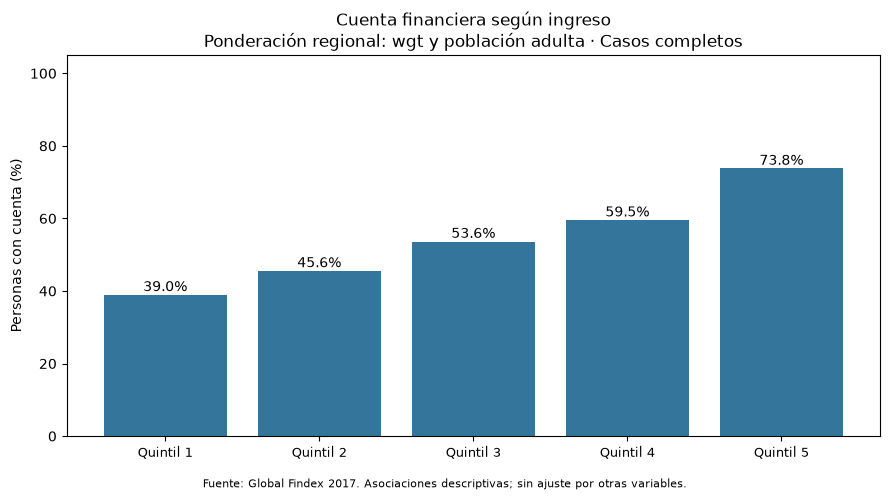

In [11]:
group_tables["inc_q"] = characteristic_table("inc_q", "account_by_income.csv")
display(group_tables["inc_q"])
plot_account_rates(group_tables["inc_q"], "etiqueta", "Cuenta financiera según ingreso",
                   FIGURES / "account_by_income.png", "Ponderación regional: wgt y población adulta")

In [12]:
show_gap(group_tables["inc_q"])

El porcentaje ponderado es mayor en **Quintil 5 (73.8%)** y menor en **Quintil 1 (39.0%)**, con una diferencia de **34.8 puntos porcentuales**. Se observa una asociación marginal; no se ha ajustado por país ni por otras características.

### Educación
Solo se presentan los tres niveles educativos válidos. `dk` y `rf` se recodificaron como faltantes antes de seleccionar casos completos.

,educ,n,con_cuenta,suma_pesos,suma_pesos_con_cuenta,sin_cuenta,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado,etiqueta,ponderacion,universo
0,1,7245,2823,1.546313e+08,6.775696e+07,4422,38.964803,43.818402,Primaria o menos,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
1,2,9801,5208,2.564763e+08,1.458654e+08,4593,53.137435,56.872837,Secundaria,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
2,3,1881,1459,4.434330e+07,3.438627e+07,422,77.565125,77.545577,Terciaria o más,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos


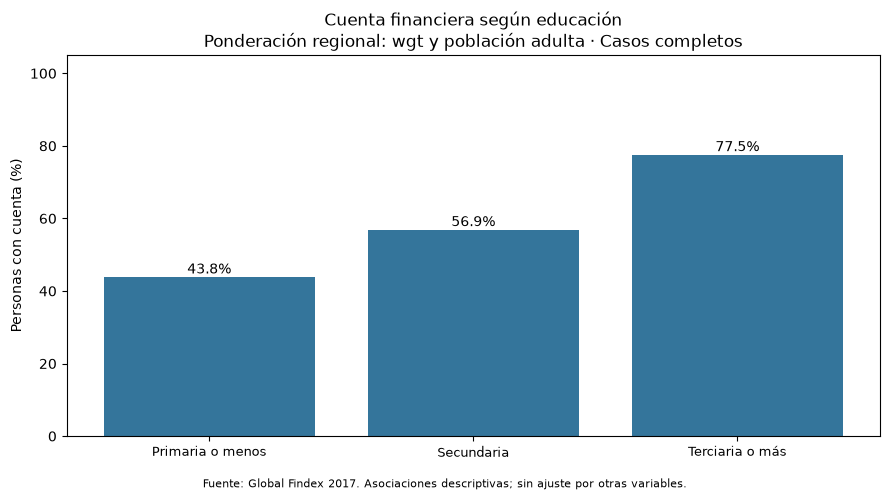

In [13]:
group_tables["educ"] = characteristic_table("educ", "account_by_education.csv")
display(group_tables["educ"])
plot_account_rates(group_tables["educ"], "etiqueta", "Cuenta financiera según educación",
                   FIGURES / "account_by_education.png", "Ponderación regional: wgt y población adulta")

In [14]:
show_gap(group_tables["educ"])

El porcentaje ponderado es mayor en **Terciaria o más (77.5%)** y menor en **Primaria o menos (43.8%)**, con una diferencia de **33.7 puntos porcentuales**. Se observa una asociación marginal; no se ha ajustado por país ni por otras características.

### Sexo
Se respeta el código original 1 = Hombre, 2 = Mujer.

,female,n,con_cuenta,suma_pesos,suma_pesos_con_cuenta,sin_cuenta,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado,etiqueta,ponderacion,universo
0,1,7537,4136,2.161459e+08,1.247615e+08,3401,54.875945,57.720976,Hombre,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
1,2,11390,5354,2.393050e+08,1.232471e+08,6036,47.006146,51.502084,Mujer,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos


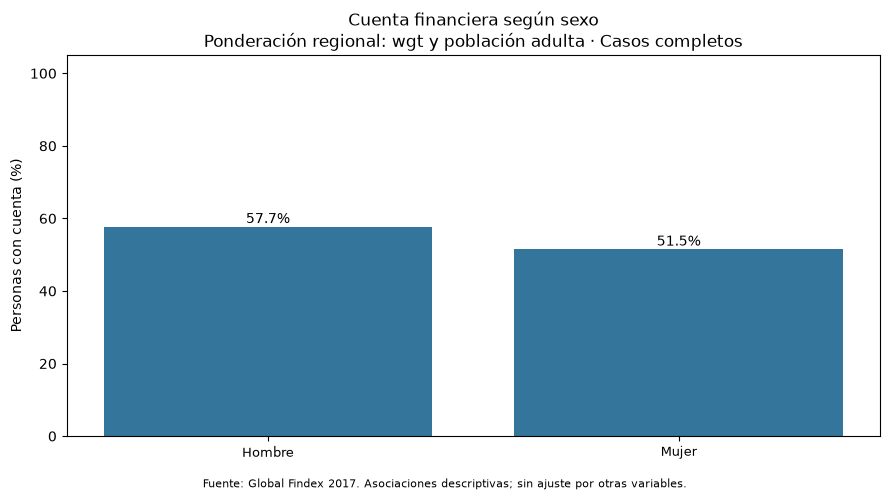

In [15]:
group_tables["female"] = characteristic_table("female", "account_by_gender.csv")
display(group_tables["female"])
plot_account_rates(group_tables["female"], "etiqueta", "Cuenta financiera según sexo",
                   FIGURES / "account_by_gender.png", "Ponderación regional: wgt y población adulta")

In [16]:
show_gap(group_tables["female"])

El porcentaje ponderado es mayor en **Hombre (57.7%)** y menor en **Mujer (51.5%)**, con una diferencia de **6.2 puntos porcentuales**. Se observa una asociación marginal; no se ha ajustado por país ni por otras características.

### Participación laboral
Estar en la fuerza laboral no equivale a estar empleado; se utiliza la definición de la variable original.

,emp_in,n,con_cuenta,suma_pesos,suma_pesos_con_cuenta,sin_cuenta,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado,etiqueta,ponderacion,universo
0,0,6479,2646,1.446240e+08,6.291405e+07,3833,40.839636,43.501812,Fuera de fuerza laboral,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
1,1,12448,6844,3.108270e+08,1.850946e+08,5604,54.980720,59.549066,En fuerza laboral,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos


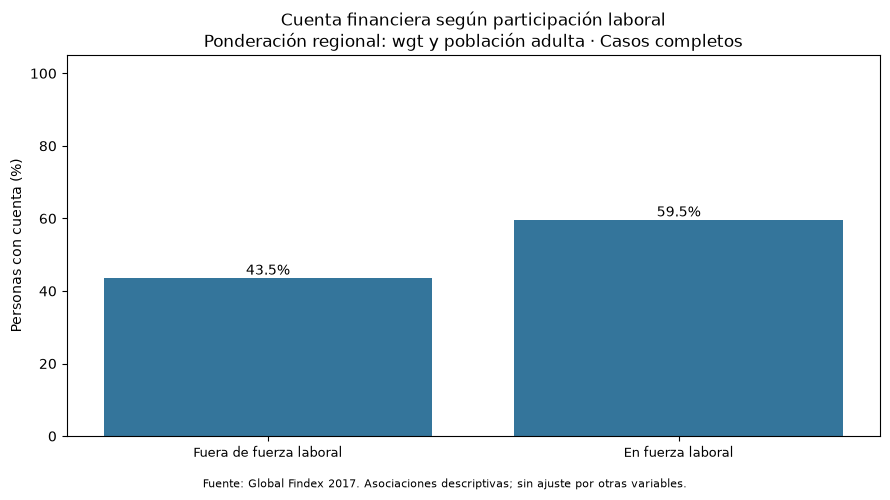

In [17]:
group_tables["emp_in"] = characteristic_table("emp_in", "account_by_employment.csv")
display(group_tables["emp_in"])
plot_account_rates(group_tables["emp_in"], "etiqueta", "Cuenta financiera según participación laboral",
                   FIGURES / "account_by_employment.png", "Ponderación regional: wgt y población adulta")

In [18]:
show_gap(group_tables["emp_in"])

El porcentaje ponderado es mayor en **En fuerza laboral (59.5%)** y menor en **Fuera de fuerza laboral (43.5%)**, con una diferencia de **16.0 puntos porcentuales**. Se observa una asociación marginal; no se ha ajustado por país ni por otras características.

### Tenencia de teléfono móvil
Se distingue tenencia de teléfono de uso de servicios financieros móviles. El código 2 significa que no posee teléfono.

,mobileowner,n,con_cuenta,suma_pesos,suma_pesos_con_cuenta,sin_cuenta,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado,etiqueta,ponderacion,universo
0,1,15060,8295,3.607974e+08,2.163664e+08,6765,55.079681,59.968938,Tiene teléfono,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos
1,2,3867,1195,9.465355e+07,3.164224e+07,2672,30.902508,33.429537,No tiene teléfono,wgt × población adulta 2016 / suma wgt origina...,LAC geográfica cubierta; casos completos


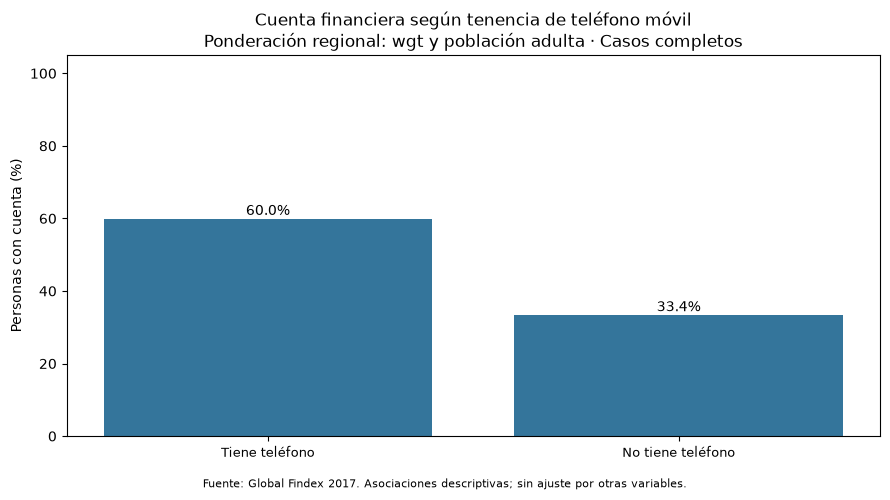

In [19]:
group_tables["mobileowner"] = characteristic_table("mobileowner", "account_by_mobile.csv")
display(group_tables["mobileowner"])
plot_account_rates(group_tables["mobileowner"], "etiqueta", "Cuenta financiera según tenencia de teléfono móvil",
                   FIGURES / "account_by_mobile.png", "Ponderación regional: wgt y población adulta")

In [20]:
show_gap(group_tables["mobileowner"])

El porcentaje ponderado es mayor en **Tiene teléfono (60.0%)** y menor en **No tiene teléfono (33.4%)**, con una diferencia de **26.5 puntos porcentuales**. Se observa una asociación marginal; no se ha ajustado por país ni por otras características.

### Edad
Se utilizan intervalos cerrados por la izquierda: 15–24, 25–34, 35–44, 45–54, 55–64 y 65+. Se conserva la edad original para el modelamiento. La tabla `age_frequencies_lac.csv` anterior permite inspeccionar la distribución por año sin descartar edades altas.

,grupo_edad,n
0,15–24,3936
1,25–34,3936
2,35–44,3234
3,45–54,2752
4,55–64,2334
5,65+,2735


,grupo_edad,n,con_cuenta,suma_pesos,suma_pesos_con_cuenta,sin_cuenta,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado,ponderacion
0,15–24,3936,1479,1.122403e+08,4.327363e+07,2457,37.576220,38.554460,wgt × población adulta 2016 / suma wgt origina...
1,25–34,3936,2171,9.998653e+07,6.186231e+07,1765,55.157520,61.870649,wgt × población adulta 2016 / suma wgt origina...
2,35–44,3234,1800,8.318020e+07,5.109724e+07,1434,55.658627,61.429576,wgt × población adulta 2016 / suma wgt origina...
3,45–54,2752,1430,6.701962e+07,4.009967e+07,1322,51.962209,59.832735,wgt × población adulta 2016 / suma wgt origina...
4,55–64,2334,1193,4.602431e+07,2.550784e+07,1141,51.113967,55.422535,wgt × población adulta 2016 / suma wgt origina...
5,65+,2735,1417,4.700000e+07,2.616790e+07,1318,51.809872,55.676384,wgt × población adulta 2016 / suma wgt origina...


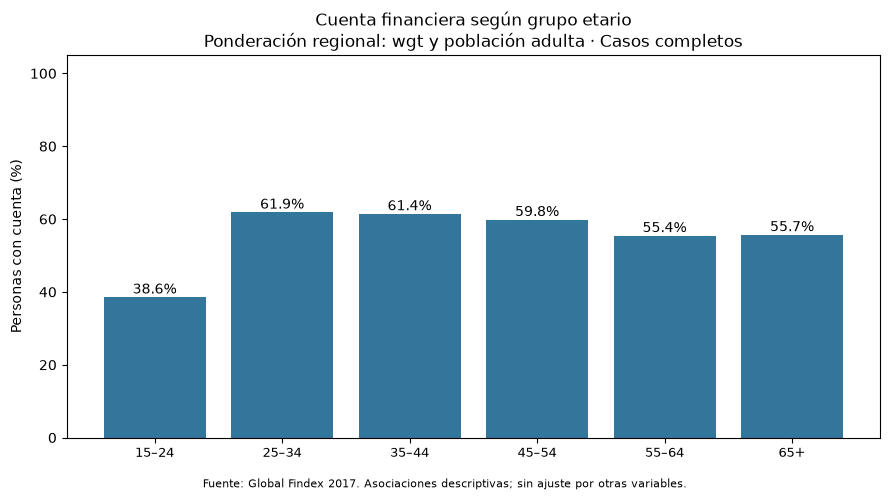

In [21]:
age_view = clean.copy()
age_view["grupo_edad"] = pd.cut(age_view.age, bins=[15, 25, 35, 45, 55, 65, np.inf], right=False,
                                labels=["15–24", "25–34", "35–44", "45–54", "55–64", "65+"])
assert age_view.grupo_edad.notna().all()
age_counts = age_view.grupo_edad.value_counts(sort=False).rename_axis("grupo_edad").reset_index(name="n")
save_table(age_counts, "age_group_distribution.csv")
display(age_counts)
age_table = account_by_group(age_view, "grupo_edad", regional_wgt)
age_table["ponderacion"] = "wgt × población adulta 2016 / suma wgt original país"
save_table(age_table, "account_by_age.csv")
display(age_table)
plot_account_rates(age_table, "grupo_edad", "Cuenta financiera según grupo etario", FIGURES / "account_by_age.png",
                   "Ponderación regional: wgt y población adulta")

In [22]:
show_gap(age_table, "grupo_edad")

El porcentaje ponderado es mayor en **25–34 (61.9%)** y menor en **15–24 (38.6%)**, con una diferencia de **23.3 puntos porcentuales**. Se observa una asociación marginal; no se ha ajustado por país ni por otras características.

### País/economía
Se ordenan las proporciones de menor a mayor para hacer visible la heterogeneidad geográfica. Cada proporción está ponderada con `wgt` dentro de su economía. El gráfico utiliza nombres en español; la tabla conserva además `economy` y `economycode` originales para facilitar la trazabilidad. La amplitud entre países describe una asociación geográfica, pero no demuestra que el país explique más que los predictores: esa comparación requiere análisis posterior.

,economy,economycode,n,con_cuenta,porcentaje_con_cuenta_no_ponderado,porcentaje_con_cuenta_ponderado
0,Haiti,HTI,503,143,28.429423,28.073613
1,Nicaragua,NIC,998,293,29.358717,28.434821
2,El Salvador,SLV,999,309,30.930931,29.372059
3,Paraguay,PRY,998,342,34.268537,31.106970
4,Mexico,MEX,991,337,34.006054,35.609416
5,Peru,PER,998,433,43.386774,42.167725
6,Honduras,HND,998,436,43.687375,42.990268
7,Guatemala,GTM,996,411,41.265060,43.554167
8,Colombia,COL,997,430,43.129388,45.091315
9,Panama,PAN,991,463,46.720484,45.946496


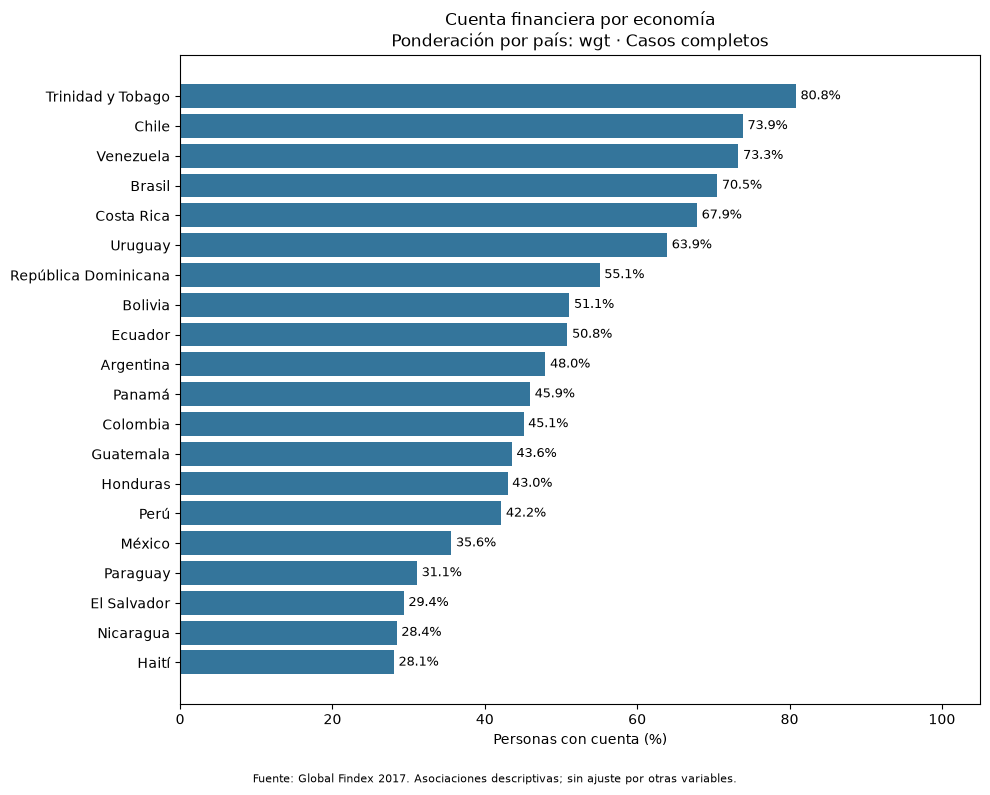

In [23]:
country_table = account_by_group(clean, "economycode", clean.wgt)
country_names = lac_economies[["economycode", "economy", "regionwb"]]
country_table = country_table.merge(country_names, on="economycode", validate="one_to_one")
country_table = country_table.sort_values("porcentaje_con_cuenta_ponderado").reset_index(drop=True)
country_table["economia_es"] = country_table.economycode.map(COUNTRY_LABELS)
assert country_table.economia_es.notna().all()
country_table["ponderacion"] = "wgt dentro de cada economía"
save_table(country_table, "account_by_country.csv")
display(country_table[["economy", "economycode", "n", "con_cuenta", "porcentaje_con_cuenta_no_ponderado", "porcentaje_con_cuenta_ponderado"]])
plot_account_rates(country_table, "economia_es", "Cuenta financiera por economía", FIGURES / "account_by_country.png",
                   "Ponderación por país: wgt", horizontal=True)

In [24]:
show_gap(country_table, "economia_es")

El porcentaje ponderado es mayor en **Trinidad y Tobago (80.8%)** y menor en **Haití (28.1%)**, con una diferencia de **52.8 puntos porcentuales**. Se observa una asociación marginal; no se ha ajustado por país ni por otras características.

## 9. Exportación y verificaciones
Se exportan únicamente el objetivo, seis predictores y cuatro auxiliares. Los códigos válidos originales se conservan: en particular, no debe interpretarse `female` o `mobileowner` como indicadores 0/1 sin recodificarlos explícitamente en la etapa de modelamiento. Ambos modelos deberán cargar **este mismo archivo**; aquí no se decide su codificación final ni se separa entrenamiento y prueba.

Las verificaciones incluyen dominios, ausencia de faltantes de modelamiento, cobertura, sumas de conteos, límites de proporciones, original intacto y concordancia exacta tras guardar y volver a leer. Las huellas de todas las tablas, figuras y del CSV procesado permiten comprobar la reproducibilidad al repetir la ejecución.

In [25]:
assert list(clean.columns) == SELECTED_COLUMNS
assert not clean[MODEL_COLUMNS].isna().any().any()
assert set(clean.educ.unique()) <= {1, 2, 3}
assert set(clean.mobileowner.unique()) <= {1, 2}
assert set(clean.account_fin.unique()) == {0, 1}
assert set(clean.economycode.unique()) == set(lac_economies.economycode)
assert len(work) - len(clean) == int(missing_rows.sum())
assert country_table.n.sum() == len(clean)
assert distribution.n.sum() == len(clean)
for table in list(group_tables.values()) + [age_table, country_table]:
    assert table.n.sum() == len(clean)
    assert table.porcentaje_con_cuenta_ponderado.between(0, 100).all()
assert np.isclose(distribution.porcentaje_ponderado_regional.sum(), 100)
clean.to_csv(PROCESSED, index=False, float_format="%.17g")
pd.testing.assert_frame_equal(clean.reset_index(drop=True), pd.read_csv(PROCESSED, float_precision="round_trip"))
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == source_hash_before
required_figures = [f"account_by_{suffix}.png" for suffix in
                    ["income", "education", "gender", "employment", "mobile", "age", "country"]]
# Solo artefactos generados por la Fase 1; no capturar outputs de fases posteriores.
required_tables = ['account_by_age.csv', 'account_by_country.csv', 'account_by_education.csv', 'account_by_employment.csv', 'account_by_gender.csv', 'account_by_income.csv', 'account_by_mobile.csv', 'account_distribution.csv', 'account_distribution_before_after.csv', 'age_frequencies_lac.csv', 'age_group_distribution.csv', 'cleaning_by_country.csv', 'cleaning_summary.csv', 'coding_verification.csv', 'data_quality_summary.csv', 'lac_economies.csv', 'missingness_patterns.csv', 'original_missing_values.csv', 'region_economy_audit.csv', 'selected_value_frequencies_original.csv', 'variable_summary_original.csv', 'weight_summary_by_country.csv']
assert all((FIGURES / name).is_file() and (FIGURES / name).stat().st_size > 0 for name in required_figures)
assert all((TABLES / name).is_file() and (TABLES / name).stat().st_size > 0 for name in required_tables)
artifacts = ([PROCESSED]
             + [TABLES / name for name in sorted(required_tables)]
             + [FIGURES / name for name in sorted(required_figures)])
artifact_hashes = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in artifacts}
(ROOT / "docs/exploration_artifacts_sha256.json").write_text(json.dumps(artifact_hashes, indent=2) + "\n", encoding="utf-8")
print(f"Base exportada: data/processed/findex_lac_clean.csv ({len(clean):,} filas × {clean.shape[1]} columnas).")
print(f"Verificaciones correctas; {len(required_figures)} figuras y {len(required_tables)} tablas guardadas.")
print("No se entrenaron modelos, no se dividieron datos ni se calcularon métricas de clasificación.")

Base exportada: data/processed/findex_lac_clean.csv (18,927 filas × 11 columnas).
Verificaciones correctas; 7 figuras y 22 tablas guardadas.
No se entrenaron modelos, no se dividieron datos ni se calcularon métricas de clasificación.


/tmp/ipykernel_50360/4073034253.py:15: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  pd.testing.assert_frame_equal(clean.reset_index(drop=True), pd.read_csv(PROCESSED, float_precision="round_trip"))


## 10. Decisiones que deben revisarse antes de modelar

1. **Cobertura:** se incluyeron CHL, URY y TTO por criterio geográfico, aunque `regionwb` los separa por ingreso. No se cubre todo el Caribe ni se replica el agregado oficial de economías en desarrollo.
2. **Objetivo:** los metadatos confirman la frecuencia y el 1 afirmativo de `account_fin`, pero dejan el 0 sin etiqueta y mantienen etiquetas 2/3 sin casos. Se usa el complemento binario observado como ausencia de tenencia registrada; no se reconstruyen no respuestas que el archivo pudo haber absorbido.
3. **Casos completos:** la eliminación es pequeña, pero no garantiza ausencia de sesgo. La selección y sus pérdidas por país están documentadas. República Dominicana presenta la mayor pérdida relativa: 47 de 1.000 observaciones (4,7%), por lo que merece revisar el patrón de no respuesta.
4. **Pesos:** descriptivos nacionales con `wgt`; descriptivos conjuntos con población adulta de 2016 y `wgt`. No se ha decidido si los futuros modelos llevarán ponderación. Las cifras ponderadas después de limpiar están condicionadas a los casos completos.
5. **Comparabilidad futura:** usar exactamente el CSV limpio para ambos modelos. Revisar la codificación de categorías, el tratamiento de edad 99+ y una estrategia de evaluación que considere heterogeneidad por economía. El país y los pesos quedan como auxiliares, fuera de los seis predictores iniciales.
6. **Interpretación:** las brechas son asociaciones marginales; no prueban causalidad, relevancia predictiva ajustada ni que el país explique más que las características individuales.

La fase termina aquí para revisión del grupo y la profesora. Los notebooks de modelos permanecen pendientes.